# Forecasting assignment - Universidad EIA (Pronósticos)

Answers to the questions of the forecasting course: autocorrelation and white noise tests, moving averages, exponential smoothing, Holt and Holt-Winters for sales data, USD/COP and the Dow Jones, EWMA volatility and VaR, and identification of AR/MA processes with the ACF and PACF.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import norm
import yfinance as yf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing as SES
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.holtwinters import ExponentialSmoothing as HWS
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_percentage_error as mape
from statsmodels.graphics.tsaplots import plot_pacf # to plot correlograms
from statsmodels.tsa.stattools import pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA
# parameters of the plots
plt.style.use('ggplot')
# plt.rcParams["figure.figsize"] = (12,10)
parameters = {'axes.labelsize': 8,
          'axes.titlesize': 10,'figure.figsize':(6,4)}
plt.rcParams.update(parameters)

# Question 1

## Part a

In [ ]:
df1 = pd.read_csv('https://raw.githubusercontent.com/wincy-guerra/EIA/main/VentasA.csv')

df1

,Unnamed: 0,Ventas_1,Ventas_2,Ventas_3
0,0,-0.332825,-0.423181,1.151455
1,1,-0.849653,-0.309749,-0.324993
2,2,-1.494727,0.491722,0.446408
3,3,-1.358865,-1.327929,0.817590
4,4,-1.456565,0.411131,-0.519810
...,...,...,...,...
245,245,-1.832523,2.032356,1.163436
246,246,-1.670692,1.691915,-0.476802
247,247,-2.103439,0.102352,0.145675
248,248,-3.698788,0.055710,0.240714


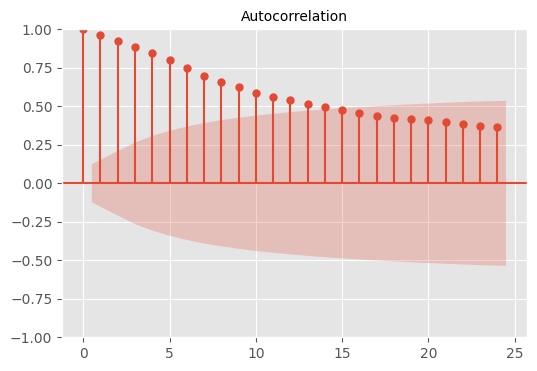

In [ ]:
plot_acf(df1.Ventas_1);

In [ ]:
# value of the function at lag 8

print(f'El valor de la funcion en el rezago 8 es: {acf(df1.Ventas_1, nlags = 8, qstat = True)[0][-1]}')


El valor de la funcion en el rezago 8 es: 0.6575251523703545


## Part b

Podemos observar que Ventas_2 es estacionaria ya que oscila alrededor de 0.


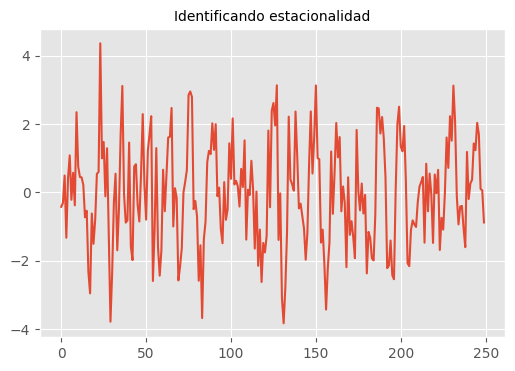

In [ ]:
# We plot it to check if Ventas_2 is seasonal or not

df1.Ventas_2.plot()

plt.title('Identificando estacionalidad');

print('Podemos observar que Ventas_2 es estacionaria ya que oscila alrededor de 0.')

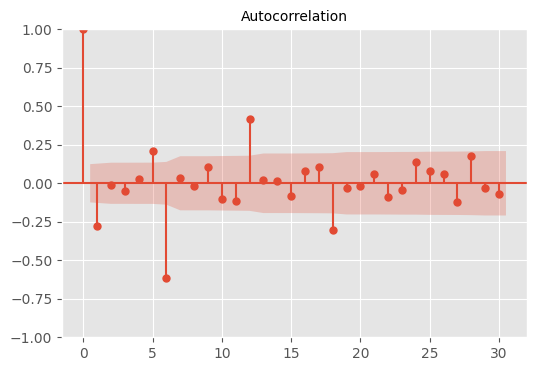

In [ ]:
plot_acf(df1.Ventas_2.diff().dropna(), lags = 30);

## Part c

In [ ]:
acf(df1['Ventas_3'],nlags=12,qstat=True)

(array([ 1.00000000e+00,  2.00169937e-02, -5.19173921e-02,  2.13086520e-02,
        -3.75091931e-02,  6.56139602e-02,  1.36154583e-02,  5.30892442e-03,
         4.51716216e-02, -9.43500632e-04, -3.81892036e-02,  5.61459653e-02,
        -2.17500707e-02]),
 array([0.10137688, 0.78609939, 0.90191192, 1.26222571, 2.36927502,
        2.41713971, 2.42444685, 2.95564499, 2.9558777 , 3.33871171,
        4.16967101, 4.29489425]),
 array([0.75018354, 0.6749952 , 0.82496639, 0.86775111, 0.79604071,
        0.87762335, 0.93267804, 0.93711012, 0.96601857, 0.97229314,
        0.96468814, 0.97750812]))

In [ ]:
# Q statistic of Ventas_3 at lag 12

acf(df1['Ventas_3'],nlags=12,qstat=True)[1][-1]

4.294894254372945

In [ ]:
# p-value of Ventas_3 at lag 12

acf(df1['Ventas_3'],nlags=12,qstat=True)[2][-1]

0.9775081157192971

As the `p_valor` is quite high, we cannot reject that all the autocorrelations are zero, so we can say that the residuals or errors of $\text{Ventas 3}$ are white noise

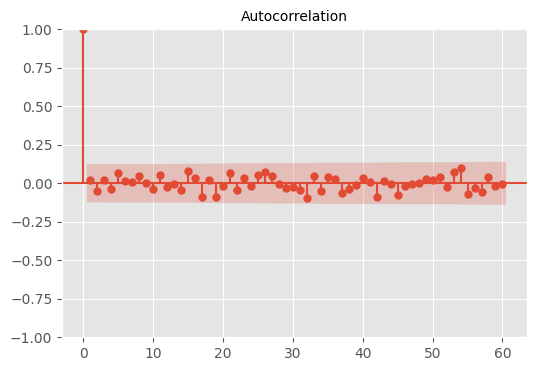

In [ ]:
plot_acf(df1.Ventas_3, lags = 60);

# Question 2

## Part a

In [ ]:
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])

y = np.array([5.3, 4.4, 5.4, 5.8, 5.6, 4.8, 5.6, 5.4, 5.9, 6.4, 6.3, 6.2, 6.9, 6.7, 5.2, 5.7, 5.9, 6.7, 6.2, 6.6])

df2 = pd.DataFrame({'Semanas' : x, 'Ventas' : y})

df2.set_index('Semanas', inplace = True)

df2

,Ventas
Semanas,
1,5.3
2,4.4
3,5.4
4,5.8
5,5.6
6,4.8
7,5.6
8,5.4
9,5.9


In [ ]:
k = 3 # Observation window: how many data points we take.

mm = pd.DataFrame()

mm['datos'] = df2.Ventas

mm['Pron'] = df2.Ventas.rolling(k).mean()

mm['resid'] = mm.datos - mm.Pron

mm.tail()

# Here we remove the .shift() so the last row shows the forecast of next week. So the forecast is 6.5 sales next week.

,datos,Pron,resid
Semanas,,,
16,5.7,5.866667,-0.166667
17,5.9,5.600000,0.300000
18,6.7,6.100000,0.600000
19,6.2,6.266667,-0.066667
20,6.6,6.500000,0.100000


## Part b

In [ ]:
suav_exp = SES(df2.Ventas).fit()

# Forecast of next week with exponential smoothing

suav_exp.forecast(10)

# The forecast is 6.355528

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


20    6.355528
21    6.355528
22    6.355528
23    6.355528
24    6.355528
25    6.355528
26    6.355528
27    6.355528
28    6.355528
29    6.355528
dtype: float64

## Part c

In [ ]:
print(f'RMSE promedio móvil: {np.sqrt(mse(df2.Ventas.iloc[3:], mm.Pron.shift().iloc[3:]))}, RMSE suavizamiento exponencial: {np.sqrt(mse(df2.Ventas, suav_exp.fittedvalues))}')

print(f'MAE promedio móvil: {mae(df2.Ventas.iloc[3:], mm.Pron.shift().iloc[3:])}, MAE suavizamiento exponencial: {mae(df2.Ventas, suav_exp.fittedvalues)}')

print(f'MAPE promedio móvil: {mape(df2.Ventas.iloc[3:], mm.Pron.shift().iloc[3:])}, MAPE suavizamiento exponencial: {mape(df2.Ventas, suav_exp.fittedvalues)}')
# Exponential smoothing is better

RMSE promedio móvil: 0.6235047473232584, RMSE suavizamiento exponencial: 0.5749742729059683
MAE promedio móvil: 0.49411764705882344, MAE suavizamiento exponencial: 0.45831035021706484
MAPE promedio móvil: 0.08446227910851867, MAPE suavizamiento exponencial: 0.08066901656876063


# Question 3

## Part a

In [ ]:
x_3 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30])

y_3 = np.array([13.3, 14.4, 10.3, 8.9, 12.5, 9.2, 11.3, 15, 18.5, 8.7, 11.5, 13.8, 10.1, 7.2, 10.1, 9.1, 14.5, 13.9, 15.9, 10.7, 16.2, 14.3, 11.6, 7.3, 9.5, 12.4, 13.4, 15.7, 12.3, 11.8])

df3 = pd.DataFrame({'Years' : x_3, 'Retornos' : y_3})

df3.set_index('Years', inplace = True)

df3

,Retornos
Years,
1,13.3
2,14.4
3,10.3
4,8.9
5,12.5
6,9.2
7,11.3
8,15.0
9,18.5


In [ ]:
k_3 = 5 # Observation window: how many data points we take.

mm_3 = pd.DataFrame()

mm_3['datos'] = df3.Retornos

mm_3['Pron'] = df3.Retornos.rolling(k_3).mean()

mm_3['resid'] = mm_3.datos - mm_3.Pron

display(mm_3.tail())

# Here we remove the .shift() so the last row shows the forecast of next week. So the forecast is 6.5 sales next week.

print('Por lo tanto, usando promedio movil de 5y obtenemos que para el 31y se espera 13.12 de rendimiento')

,datos,Pron,resid
Years,,,
26,12.4,11.02,1.38
27,13.4,10.84,2.56
28,15.7,11.66,4.04
29,12.3,12.66,-0.36
30,11.8,13.12,-1.32


Por lo tanto, usando promedio movil de 5y obtenemos que para el 31y se espera 13.12 de rendimiento


In [ ]:
print(f'RMSE promedio móvil: {np.sqrt(mse(df3.Retornos.iloc[5:], mm_3.Pron.shift().iloc[5:]))}')

print(f'MAE promedio móvil: {mae(df3.Retornos.iloc[5:], mm_3.Pron.shift().iloc[5:])}')

print(f'MAPE promedio móvil: {mape(df3.Retornos.iloc[5:], mm_3.Pron.shift().iloc[5:])}')

RMSE promedio móvil: 3.476826138880114
MAE promedio móvil: 2.832
MAPE promedio móvil: 0.2497867095713987


## Part b

In [ ]:
suav_exp_3 = SES(df3.Retornos).fit()

# Forecast of next year with exponential smoothing

suav_exp_3.forecast(10)

# The forecast is 12.431167

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided and will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


30    12.431167
31    12.431167
32    12.431167
33    12.431167
34    12.431167
35    12.431167
36    12.431167
37    12.431167
38    12.431167
39    12.431167
dtype: float64

In [ ]:
print(f'RMSE promedio móvil: {np.sqrt(mse(df3.Retornos, suav_exp_3.fittedvalues))}')

print(f'MAE promedio móvil: {mae(df3.Retornos, suav_exp_3.fittedvalues)}')

print(f'MAPE promedio móvil: {mape(df3.Retornos, suav_exp_3.fittedvalues)}')

RMSE promedio móvil: 2.898030579253016
MAE promedio móvil: 2.415328509784599
MAPE promedio móvil: 0.22516365542875408


## Part c

In [ ]:
suav_exp_3.summary()

# the best method is simple exponential smoothing.
# the MAE tells us that the average size of the errors of the model is 2.42%, so each forecast deviates around 2.42% from the real data
# alpha is close to 0, so the out-of-sample forecast gives more weight to the last forecast than to the last observation. The forecast says future returns will be around 12.43%

Dep. Variable:,Retornos,No. Observations:,30
Model:,SimpleExpSmoothing,SSE,251.957
Optimized:,True,AIC,67.842
Trend:,None,BIC,70.644
Seasonal:,None,AICC,69.442
Seasonal Periods:,None,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:02:56
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.0519361,alpha,True
initial_level,13.300000,l.0,False


## Part d

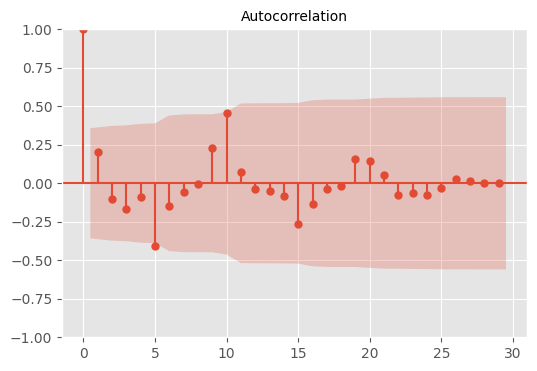

In [ ]:
# residuals of the model

resid_3 = suav_exp_3.resid

#display(resid_3)

# correlogram

plot_acf(resid_3, lags = 29);

# It is not clear if they are white noise, so we use the Ljung-Box test

In [ ]:
acf(resid_3,nlags=30,qstat=True)

(array([ 1.00000000e+00,  2.04412339e-01, -1.02219941e-01, -1.69910739e-01,
        -9.22019993e-02, -4.10071903e-01, -1.50445945e-01, -5.51658408e-02,
        -4.63793442e-03,  2.31999525e-01,  4.58775948e-01,  7.18728620e-02,
        -3.68207415e-02, -4.71603544e-02, -8.15090418e-02, -2.65636460e-01,
        -1.36715090e-01, -4.03249427e-02, -1.82312967e-02,  1.55270067e-01,
         1.46699066e-01,  5.12517272e-02, -7.56113627e-02, -6.41982866e-02,
        -7.75648755e-02, -3.33035286e-02,  2.87269786e-02,  1.28290826e-02,
         1.41164666e-04, -2.48476664e-04]),
 array([ 1.38320786,  1.74145643,  2.7679332 ,  3.08182398,  9.53912827,
        10.44448756, 10.571511  , 10.57244964, 13.03296527, 23.13578306,
        23.39678727, 23.46909485, 23.59469103, 23.99331446, 28.50932911,
        29.79099877, 29.91108007, 29.93767049, 32.04171066, 34.1076898 ,
        34.38787535, 35.07392473, 35.63914805, 36.60175763, 36.81470964,
        37.01276707, 37.06543438, 37.06544395, 37.06550322]

In [ ]:
# Ljung-Box test with 30 lags

display(acf(resid_3,nlags=30,qstat=True)[0][-1])

display(acf(resid_3,nlags=30,qstat=True)[1][-1])

display(acf(resid_3,nlags=30,qstat=True)[2][-1])

print('Podemos observar que el p_valor es bastante alto (>0.05) por lo que no podemos rechazar que todas las autocorrelaciones sean cero, es decir, si es ruido blanco')

-0.00024847666363539097

37.06550321831442

0.14455614284399848

Podemos observar que el p_valor es bastante alto (>0.05) por lo que no podemos rechazar que todas las autocorrelaciones sean cero, es decir, si es ruido blanco


# Question 4

## Part a

In [ ]:
import yfinance as yf

df_4 = yf.download('USDCOP=X', start='2014-01-01',end='2024-05-13')[['Close']]

Precio = df_4.resample('M').last()

Precio.tail()


[*********************100%%**********************]  1 of 1 completed


,Close
Date,
2024-01-31,3919.260010
2024-02-29,3923.189941
2024-03-31,3857.250000
2024-04-30,3907.260010
2024-05-31,3888.760010


In [ ]:
Precio.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 125 entries, 2014-01-31 to 2024-05-31
Freq: M
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   125 non-null    float64
dtypes: float64(1)
memory usage: 2.0 KB


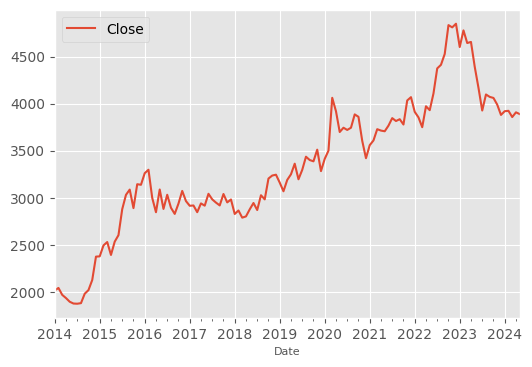

In [ ]:
Precio.plot();

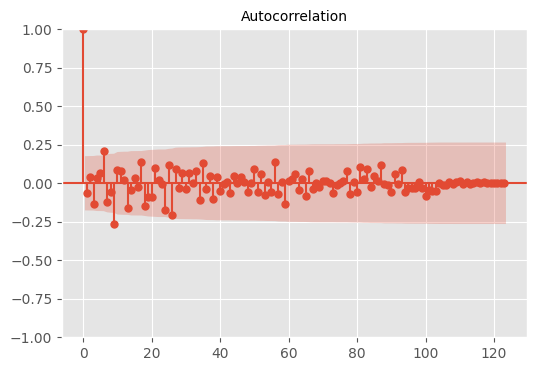

In [ ]:
plot_acf(Precio.diff().dropna(), lags = 123); # We confirm it is not seasonal, there is no clear seasonal component

In [ ]:
print('Con el plot podemos observar que la serie no es estacional, debido a que no oscila al rededor de un valor especifico')

Con el plot podemos observar que la serie no es estacional, debido a que no oscila al rededor de un valor especifico


## Part b

### Simple average

In [ ]:
ms =  pd.DataFrame() # empty dataframe

ms['datos'] = Precio.Close

ms['pron'] = Precio.Close.cumsum().div(np.arange(1, len(ms) + 1))

ms['resid'] = ms.datos - ms.pron

ms.head()

# Removing the .shift() we get that the forecast for 30 June 2024 is 3371.51

,datos,pron,resid
Date,,,
2014-01-31,2016.0,2016.000000,0.000000
2014-02-28,2042.5,2029.250000,13.250000
2014-03-31,1969.0,2009.166667,-40.166667
2014-04-30,1935.0,1990.625000,-55.625000
2014-05-31,1896.0,1971.700000,-75.700000


In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close.iloc[1:], ms.pron.shift().iloc[1:]))}')
print(f'MAE: {mae(Precio.Close.iloc[1:], ms.pron.shift().iloc[1:])}')
print(f'MAPE: {mape(Precio.Close.iloc[1:], ms.pron.shift().iloc[1:])}')

RMSE: 716.4771298298771
MAE: 614.1128516450667
MAPE: 0.17107536108019814


### Moving average

In [ ]:
k_4 = 12 # Observation window: how many data points we take.

# We can change K depending on what we need

mm = pd.DataFrame()

mm['datos'] = Precio.Close

mm['pron'] = Precio.Close.rolling(k_4).mean()

mm['resid'] = mm.datos - mm.pron

mm.tail()

# Removing the .shift() we get that the forecast for 30 June 2024 is 3973.68

,datos,pron,resid
Date,,,
2024-01-31,3919.260010,4214.711650,-295.451640
2024-02-29,3923.189941,4143.539164,-220.349223
2024-03-31,3857.250000,4078.039164,-220.789164
2024-04-30,3907.260010,4015.748332,-108.488322
2024-05-31,3888.760010,3973.874166,-85.114156


In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close.iloc[12:], mm.pron.shift().iloc[12:]))}')
print(f'MAE: {mae(Precio.Close.iloc[12:], mm.pron.shift().iloc[12:])}')
print(f'MAPE: {mape(Precio.Close.iloc[12:], mm.pron.shift().iloc[12:])}')

RMSE: 301.49243682080566
MAE: 234.8896724734686
MAPE: 0.06707418022751788


### Double moving average

In [ ]:
# Double moving average

k_4_1 = 12 # Observation window

# Columns of the double moving average DataFrame

mmd = pd.DataFrame() # empty DataFrame

mmd['datos'] = Precio.Close

mmd['mm'] = mmd.rolling(k_4_1)['datos'].mean() # moving average of the data

mmd['pmm'] = mmd.mm # forecast with moving average

mmd['mmp'] = mmd.rolling(k_4_1)['mm'].mean() # moving average of the moving average

# a_t and b_t

a_t = 2*mmd.mm - mmd.mmp

b_t = (2/(k_4_1-1))*(mmd.mm - mmd.mmp)

# column with the forecasts

mmd['pron'] = (a_t + b_t) # The .shift() is needed because we are forecasting. These are the in-sample forecasts

mmd.tail()

# The forecast is 3586.69

,datos,mm,pmm,mmp,pron
Date,,,,,
2024-01-31,3919.260010,4214.711650,4214.711650,4452.069277,3934.198090
2024-02-29,3923.189941,4143.539164,4143.539164,4429.728863,3805.314975
2024-03-31,3857.250000,4078.039164,4078.039164,4395.722755,3702.594921
2024-04-30,3907.260010,4015.748332,4015.748332,4351.781299,3618.618461
2024-05-31,3887.250000,3973.748332,3973.748332,4301.137829,3586.833471


In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close.iloc[23:], mmd.pron.shift().iloc[23:]))}')
print(f'MAE: {mae(Precio.Close.iloc[23:], mmd.pron.shift().iloc[23:])}')
print(f'MAPE: {mape(Precio.Close.iloc[23:], mmd.pron.shift().iloc[23:])}')

RMSE: 274.6817770914011
MAE: 193.8274902166955
MAPE: 0.05361982403853738


### Exponential smoothing

In [ ]:
exp_s_4 = SES(Precio.Close).fit()

exp_s_4.summary()

Dep. Variable:,Close,No. Observations:,125
Model:,SimpleExpSmoothing,SSE,2321605.968
Optimized:,True,AIC,1232.682
Trend:,None,BIC,1238.339
Seasonal:,None,AICC,1233.015
Seasonal Periods:,None,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:03:02
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.9516611,alpha,True
initial_level,2016.0000,l.0,False


In [ ]:
exp_s_4.forecast(1)

# The forecast is 3887.34

2024-06-30    3888.107823
Freq: M, dtype: float64

In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close, exp_s_4.fittedvalues))}')
print(f'MAE: {mae(Precio.Close, exp_s_4.fittedvalues)}')
print(f'MAPE: {mape(Precio.Close, exp_s_4.fittedvalues)}')

RMSE: 136.2822356037859
MAE: 103.39878000999883
MAPE: 0.031192250046323634


### Holt

In [ ]:
holt_4 = Holt(Precio.Close).fit()

holt_4.summary()

Dep. Variable:,Close,No. Observations:,125
Model:,Holt,SSE,2308813.264
Optimized:,True,AIC,1235.991
Trend:,Additive,BIC,1247.305
Seasonal:,None,AICC,1236.703
Seasonal Periods:,None,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:03:03
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.9456995,alpha,True
smoothing_trend,2.9611e-05,beta,True


In [ ]:
holt_4.forecast(1)

# The forecast is 3891.17

2024-06-30    3916.176251
Freq: M, dtype: float64

In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close, holt_4.fittedvalues))}')
print(f'MAE: {mae(Precio.Close, holt_4.fittedvalues)}')
print(f'MAPE: {mape(Precio.Close, holt_4.fittedvalues)}')

RMSE: 135.9062401542712
MAE: 103.7820161858879
MAPE: 0.031440696993565734


### Holt-Winters

In [ ]:
# Additive Holt-Winters

hw1 = HWS(Precio.Close, trend = 'add', seasonal = 'add').fit() # additive seasonal component
hw1.summary()

Dep. Variable:,Close,No. Observations:,125
Model:,ExponentialSmoothing,SSE,2431666.895
Optimized:,True,AIC,1266.472
Trend:,Additive,BIC,1311.725
Seasonal:,Additive,AICC,1272.925
Seasonal Periods:,12,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:03:03
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.8701530,alpha,True
smoothing_trend,0.0679314,beta,True


In [ ]:
hw1.forecast(1)

# The forecast is 3892.76

2024-06-30    3872.105036
Freq: M, dtype: float64

In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close, hw1.fittedvalues))}')
print(f'MAE: {mae(Precio.Close, hw1.fittedvalues)}')
print(f'MAPE: {mape(Precio.Close, hw1.fittedvalues)}')

RMSE: 139.47521343621395
MAE: 105.56264144036957
MAPE: 0.031742750169545635


In [ ]:
# Multiplicative Holt-Winters

hw2 = HWS(Precio.Close, trend = 'add', seasonal = 'mul').fit() # additive seasonal component
hw2.summary()

Dep. Variable:,Close,No. Observations:,125
Model:,ExponentialSmoothing,SSE,2470023.506
Optimized:,True,AIC,1268.428
Trend:,Additive,BIC,1313.681
Seasonal:,Multiplicative,AICC,1274.881
Seasonal Periods:,12,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:03:04
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.8450359,alpha,True
smoothing_trend,0.0321765,beta,True


In [ ]:
hw2.forecast(1)

# The forecast is 3855.04

2024-06-30    3873.954647
Freq: M, dtype: float64

In [ ]:
print(f'RMSE: {np.sqrt(mse(Precio.Close, hw2.fittedvalues))}')
print(f'MAE: {mae(Precio.Close, hw2.fittedvalues)}')
print(f'MAPE: {mape(Precio.Close, hw2.fittedvalues)}')

RMSE: 140.57093599014945
MAE: 110.11315619220474
MAPE: 0.03326705004135001


The worst forecasts are the simple average, the moving average and the double moving average (in that order). Simple exponential smoothing is the best model, with an error of around 3% (105 pesos). After it come Holt, additive Holt-Winters and multiplicative Holt-Winters. As simple exponential smoothing is the most useful, the most recent data have more weight in the forecast, and the data have no trend and no seasonal component.

# Question 5

## Part a

In [ ]:
# First DataFrame

import yfinance as yf

df_5 = yf.download('^DJI', start = '2004-01-01', end = '2024-05-10')[['Close']]

df_5['Ret'] = df_5.Close.pct_change()

df_5['log'] = np.log(df_5.Close) - np.log(df_5.Close.shift(1))

df_5.tail(10)

[*********************100%%**********************]  1 of 1 completed
<ipython-input-80-a6ff2357c8d7>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_5['Ret'] = df_5.Close.pct_change()
<ipython-input-80-a6ff2357c8d7>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_5['log'] = np.log(df_5.Close) - np.log(df_5.Close.shift(1))


,Close,Ret,log
Date,,,
2024-04-26,38239.660156,0.004040,0.004032
2024-04-29,38386.089844,0.003829,0.003822
2024-04-30,37815.921875,-0.014854,-0.014965
2024-05-01,37903.289062,0.002310,0.002308
2024-05-02,38225.660156,0.008505,0.008469
2024-05-03,38675.679688,0.011773,0.011704
2024-05-06,38852.269531,0.004566,0.004556
2024-05-07,38884.261719,0.000823,0.000823
2024-05-08,39056.390625,0.004427,0.004417


## Part b

In [ ]:
# We convert the data to monthly

df_5_p = pd.DataFrame()

df_5_p['Vol'] = (df_5.log**2).resample('M').sum()

df_5_p

,Vol
Date,
2004-01-31,0.001123
2004-02-29,0.000440
2004-03-31,0.001942
2004-04-30,0.001084
2004-05-31,0.000970
...,...
2024-01-31,0.000509
2024-02-29,0.000652
2024-03-31,0.000661


In [ ]:
df_5_p.Vol[-1]

0.0003263528954914435

In [ ]:
df_5.log[-1]**2 + df_5.log[-2]**2 + df_5.log[-3]**2 + df_5.log[-4]**2 + df_5.log[-5]**2 + df_5.log[-6]**2 + df_5.log[-7]**2

0.0003263528954914435

## Part d

In [ ]:
# Parameters we need

EWMA = SES(df_5_p.Vol).fit(smoothing_level=0.97)
EWMA.forecast()

/usr/local/lib/python3.10/dist-packages/pandas/util/_decorators.py:210: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


2024-06-30    0.000352
Freq: M, dtype: float64

In [ ]:
EWMA.summary()

Dep. Variable:,Vol,No. Observations:,245
Model:,SimpleExpSmoothing,SSE,0.015
Optimized:,False,AIC,-2378.852
Trend:,None,BIC,-2371.849
Seasonal:,None,AICC,-2378.685
Seasonal Periods:,None,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:34:04
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.9700000,alpha,False
initial_level,0.0011228,l.0,False


## Part e

In [ ]:
# Forecast with exponential smoothing and the best alpha

exp_s_5 = SES(df_5_p.Vol).fit()

display(exp_s_5.summary())

exp_s_5.forecast(1)

# The forecast is 0.000734

Dep. Variable:,Vol,No. Observations:,245
Model:,SimpleExpSmoothing,SSE,0.011
Optimized:,True,AIC,-2440.851
Trend:,None,BIC,-2433.849
Seasonal:,None,AICC,-2440.685
Seasonal Periods:,None,Date:,"Thu, 16 May 2024"
Box-Cox:,False,Time:,13:34:07
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.2467442,alpha,True
initial_level,0.0011228,l.0,False


2024-06-30    0.000741
Freq: M, dtype: float64

In [ ]:
# Forecast with moving averages and k = 24

k_5 = 24 # Observation window: how many data points we take.

# We can change K depending on what we need

mm_5 = pd.DataFrame()

mm_5['datos'] = df_5_p.Vol

mm_5['pron_intra'] = df_5_p.Vol.rolling(k_5).mean().shift()

mm_5['pron_extra'] = df_5_p.Vol.rolling(k_5).mean()

mm_5['resid_intra'] = np.var(mm_5.datos - mm_5.pron_intra)

mm_5['resid_extra'] = np.var(mm_5.datos - mm_5.pron_extra)

mm_5.tail()

# Removing the .shift() we get that the forecast for June is 0.001661

,datos,pron_intra,pron_extra,resid_intra,resid_extra
Date,,,,,
2024-01-31,0.000509,0.002166,0.002132,0.000056,0.000052
2024-02-29,0.000652,0.002132,0.002055,0.000056,0.000052
2024-03-31,0.000661,0.002055,0.001948,0.000056,0.000052
2024-04-30,0.001185,0.001948,0.001858,0.000056,0.000052
2024-05-31,0.000326,0.001858,0.001659,0.000056,0.000052


In [ ]:
# Double moving average

k_5_1 = 24 # Observation window

# Columns of the double moving average DataFrame

mm5 = pd.DataFrame() # empty DataFrame

mm5['datos'] = df_5_p.Vol

mm5['mm'] = mm5.rolling(k_5_1)['datos'].mean() # moving average of the data

mm5['pmm'] = mm5.mm # forecast with moving average

mm5['mmp'] = mm5.rolling(k_5_1)['mm'].mean() # moving average of the moving average

# a_t and b_t

a_t_5 = 2*mm5.mm - mm5.mmp

b_t_5 = (2/(k_5_1-1))*(mm5.mm - mm5.mmp)

# column with the forecasts

mm5['pron'] = (a_t_5 + b_t_5) # The .shift() is needed because we are forecasting. These are the in-sample forecasts

mm5.tail()

# The forecast is 3586.69

,datos,mm,pmm,mmp,pron
Date,,,,,
2024-01-31,0.000509,0.002132,0.002132,0.002417,0.001822
2024-02-29,0.000652,0.002055,0.002055,0.002243,0.001850
2024-03-31,0.000661,0.001948,0.001948,0.002208,0.001664
2024-04-30,0.001185,0.001858,0.001858,0.002189,0.001498
2024-05-31,0.000326,0.001659,0.001659,0.002162,0.001111


## Part f

In [ ]:
# HRMSE for EWMA

np.sqrt((1/len(df_5_p.Vol))*np.sum((1-(np.var(df_5_p.Vol)/np.var(EWMA.fittedvalues)))**2))

0.002071927598499526

In [ ]:
# HRMSE for exponential smoothing

np.sqrt((1/len(df_5_p.Vol))*np.sum((1-(np.var(df_5_p.Vol)/np.var(exp_s_5.fittedvalues)))**2))

0.1619097945571665

In [ ]:
# HRMSE for moving averages

np.sqrt((1/len(df_5_p.Vol.iloc[24:]))*np.sum((1-(np.var(df_5_p.Vol.iloc[24:])/np.var(mm_5.pron_extra.shift().iloc[24:])))**2))

0.5738653413940535

In [ ]:
# HRMSE for double moving averages

np.sqrt((1/len(df_5_p.Vol.iloc[24:]))*np.sum((1-(np.var(df_5_p.Vol.iloc[24:])/np.var(mm5.pron.shift().iloc[24:])))**2))

0.13694028923096993

## Part g

In [ ]:
# Conditions for the VaR

alpha = 0.05

Za = norm.ppf(1 - alpha)

Za

1.6448536269514722

In [ ]:
# VaR with EWMA

VaR_EWMA = df_5.Close[-1]*Za*EWMA.forecast(1)

VaR_EWMA

2024-06-30    22.78158
Freq: M, dtype: float64

In [ ]:
# VaR with exponential smoothing

VaR_exp_s = df_5.Close[-1]*Za*exp_s_5.forecast(1)

VaR_exp_s

2024-06-30    47.98313
Freq: M, dtype: float64

In [ ]:
# VaR with moving average

VaR_mm = df_5.Close[-1]*Za*mm_5.pron_extra[-1]

VaR_mm

107.45208534967345

# Question 6

# Question 7

## Part a

In [ ]:
import numpy as np
import statsmodels.tsa.stattools as ts

np.random.seed(123)
ma_7 = np.array([1])
ar_7 = np.array([1, 1.7, 0.8])
AR_object_7 = ArmaProcess(ar_7, ma_7)
data_7 = AR_object_7.generate_sample(nsample=5000)


In [ ]:
display(np.abs(AR_object_7.arroots))

print('Como las raices dan mayor a uno, entonces es estacionario')

array([1.11803399, 1.11803399])

Como las raices dan mayor a uno, entonces es estacionario


## Part b

In [ ]:
# Simulation
acf = sm.tsa.acf(data_7, nlags=7)

# Print the ACF
print(acf)

[ 1.         -0.94552229  0.80848919 -0.61695431  0.39860391 -0.17922051
 -0.01942816  0.18113307]


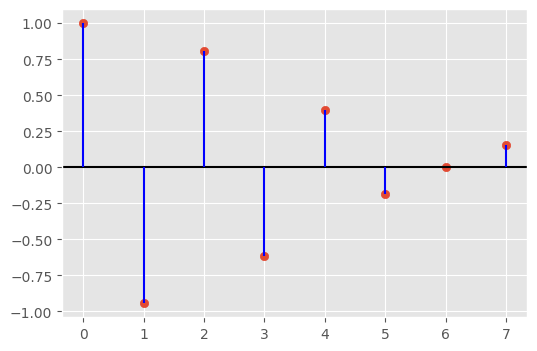

In [ ]:
# Data of the picture (exercise statement)

x1=[0,1,2,3,4,5,6,7]
y1=[1,-0.944,0.805,-0.614,0.399,-0.187,-0.0013,0.152]
plt.scatter(x1,y1)
plt.axhline(y=0, color='black')
for i in x1:
  plt.vlines(x=x1[i],ymin=0,ymax=y1[i],color='blue')
plt.show()

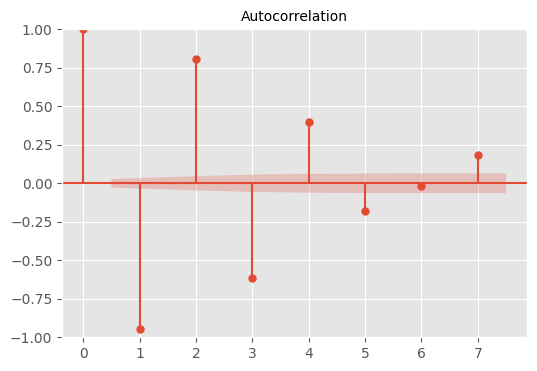

In [ ]:
# Data of the simulation

plot_acf(data_7, lags = 7);

## Part c

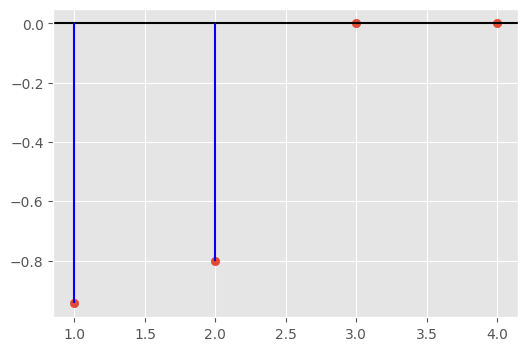

In [ ]:
# How the data of the picture look

x11=[1,2,3,4]
y11=[-0.944,-0.8,0,0]
plt.scatter(x11,y11)
plt.axhline(y=0, color='black')
for i in range(len(x11)):
  plt.vlines(x=x11[i],ymin=0,ymax=y11[i],color='blue')
plt.show()

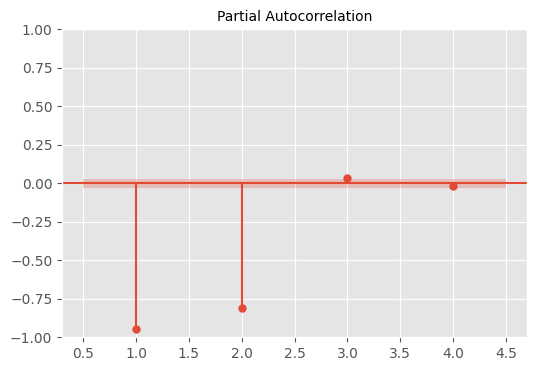

In [ ]:
# Data of one simulation

plot_pacf(data_7, lags = 4, zero = False);

# Question 8

## Part a

In [ ]:
import numpy as np
import statsmodels.tsa.stattools as ts

np.random.seed(123)
ma_8 = np.array([1])
ar_8 = np.array([1, -1.45, +0.9])
AR_object_8 = ArmaProcess(ar_8, ma_8)
data_8 = AR_object_8.generate_sample(nsample=5000)


In [ ]:
display(np.abs(AR_object_8.arroots))

print('Como las raices dan mayor a uno, entonces es estacionario')

array([1.05409255, 1.05409255])

Como las raices dan mayor a uno, entonces es estacionario


## Part b

In [ ]:
# Simulation
acf_8 = sm.tsa.acf(data_8, nlags=7)

# Print the ACF
print(acf_8)

[ 1.          0.76254578  0.20283638 -0.39392306 -0.75306141 -0.73642861
 -0.38796237  0.10184762]


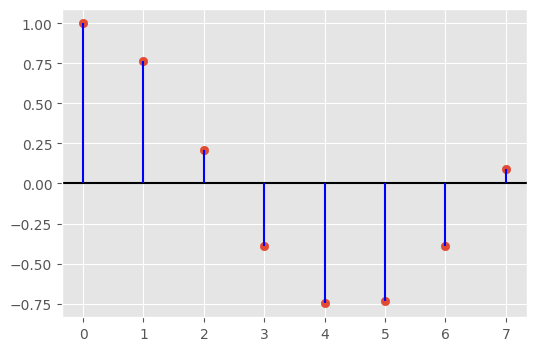

In [ ]:
# Data of the picture (exercise statement)

x2=[0,1,2,3,4,5,6,7]
y2=[1,0.763,0.206,-0.388,-0.748,-0.735,-0.393,0.092]
plt.scatter(x2,y2)
plt.axhline(y=0, color='black')
for i in x2:
  plt.vlines(x=x2[i],ymin=0,ymax=y2[i],color='blue')
plt.show()

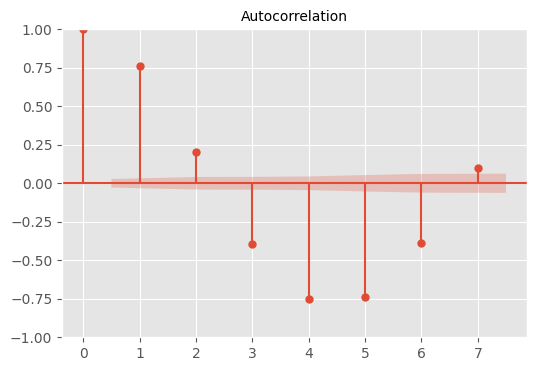

In [ ]:
# Data of the simulation

plot_acf(data_8, lags = 7);

## Part c

In [ ]:
# Simulation
pacf_8 = sm.tsa.pacf(data_8, nlags=4)

# Print the ACF
print(pacf_8)

[ 1.          0.76269831 -0.90556793  0.02126468  0.00791153]


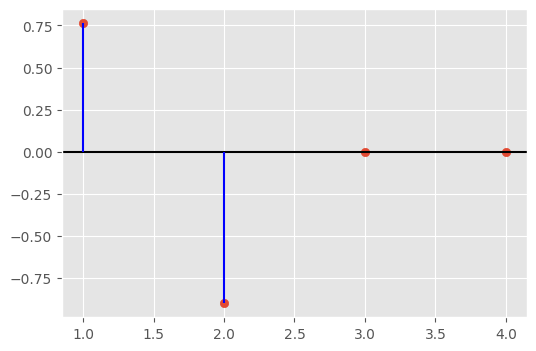

In [ ]:
# Data of the notebook

x22=[1,2,3,4]
y22=[0.763,-0.9,0,0]
plt.scatter(x22,y22)
plt.axhline(y=0, color='black')
for i in range(len(x22)):
  plt.vlines(x=x22[i],ymin=0,ymax=y22[i],color='blue')
plt.show()

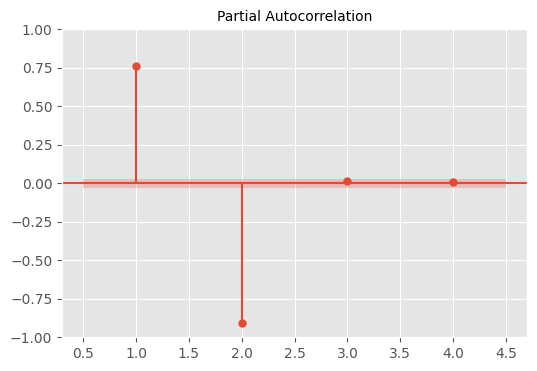

In [ ]:
# Data of the picture (exercise statement)

plot_pacf(data_8, lags = 4, zero = False);